In [1]:
# install rdkit
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.7/36.7 MB 23.1 MB/s eta 0:00:00


In [2]:
## Given a set of compounds, identify their common substructures using the following simple method:
## We use the Breaking Retrosynthetically Interesting Chemical Substructures (BRICS) method (as implemented in RDKit)
## to decompose each compound into chemical fragments. The histogram of the chemical fragments can give us frequent substructures in the set of molecules.

## import the csv with compound SMILES strings
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools

df = pd.read_csv('caspase_and_mito_Active.csv')

PandasTools.AddMoleculeColumnToFrame(df, 'PUBCHEM_EXT_DATASOURCE_SMILES', 'Molecule')

print(df[['PUBCHEM_EXT_DATASOURCE_SMILES', 'Molecule']].head())

/tmp/ipython-input-3978802861.py:10: DtypeWarning: Columns (13,20,48,55,83,90,123,130,158,165,193,200,232,239,267,274,302,309,336,341,348,376,383,411,418,445,450,457,485,492,520,527,554,559,566,594,601,629,636,663,668,675,703,710,738,745,772,777,784,812,819,847,854,881,886,893,921,928,956,963,990,995,1002,1030,1037,1065,1072,1099,1104,1111,1139,1146,1174,1181,1208,1213,1220,1248,1255,1283,1290,1317,1322,1329,1357,1364,1392,1399,1426,1431,1438,1466,1473,1501,1508,1535,1540,1547,1575,1582,1610,1617,1644,1649,1656,1684,1691,1719,1726,1753,1758,1765,1793,1800,1828,1835,1862,1867,1874,1902,1909,1937,1944,1971,1976,1983,2011,2018,2046,2053,2080,2085,2092,2120,2127,2155,2162,2189,2194,2201,2229,2236,2264,2271,2298,2303,2310,2338,2345,2373,2380,2407,2412,2419,2447,2454,2482,2489,2516,2521,2528,2556,2563,2591,2598,2625,2630,2637,2665,2672,2700,2707,2734,2739,2746,2774,2781,2809,2816,2843,2848,2855,2883,2890,2918,2925,2952,2957,2964,2992,2999,3027,3034,3061,3066,3073,3101,3108,3136,3143,3170,317

                       PUBCHEM_EXT_DATASOURCE_SMILES  \
0  C1(=O)C2(C3(C4(C1(C5(C2(C3(C(C45Cl)(Cl)Cl)Cl)C...   
1         CC1=C2CCC3=C2C(=CC4=C3C=CC5=CC=CC=C54)C=C1   
2                            CCCCCCCCCC1=CC=C(C=C1)O   
3                           C1=CC2=C(C(=C1)O)N=CC=C2   
4                  CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC   

                                           Molecule  
0  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fb50>  
1  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fbc0>  
2  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fc30>  
3  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fca0>  
4  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fd10>  


In [3]:
from rdkit.Chem import AllChem

# Function to generate Morgan fingerprint (ECFP4) as a bit vector
def get_morgan_fingerprint(mol):
    if mol is not None:
        return AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048) # Radius 2, 2048 bits
    return None

# Apply the function to the 'Molecule' column to create a new 'Morgan_Fingerprint' column
df['Morgan_Fingerprint'] = df['Molecule'].apply(get_morgan_fingerprint)

print(df[['PUBCHEM_EXT_DATASOURCE_SMILES', 'Molecule', 'Morgan_Fingerprint']].head())

                       PUBCHEM_EXT_DATASOURCE_SMILES  \
0  C1(=O)C2(C3(C4(C1(C5(C2(C3(C(C45Cl)(Cl)Cl)Cl)C...   
1         CC1=C2CCC3=C2C(=CC4=C3C=CC5=CC=CC=C54)C=C1   
2                            CCCCCCCCCC1=CC=C(C=C1)O   
3                           C1=CC2=C(C(=C1)O)N=CC=C2   
4                  CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC   

                                           Molecule  \
0  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fb50>   
1  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fbc0>   
2  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fc30>   
3  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fca0>   
4  <rdkit.Chem.rdchem.Mol object at 0x7a1524e2fd10>   

                                  Morgan_Fingerprint  
0  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
1  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
2  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
3  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
4  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ...  


[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerator
[22:59:53] DEPRECATION WARNING: please use MorganGenerat

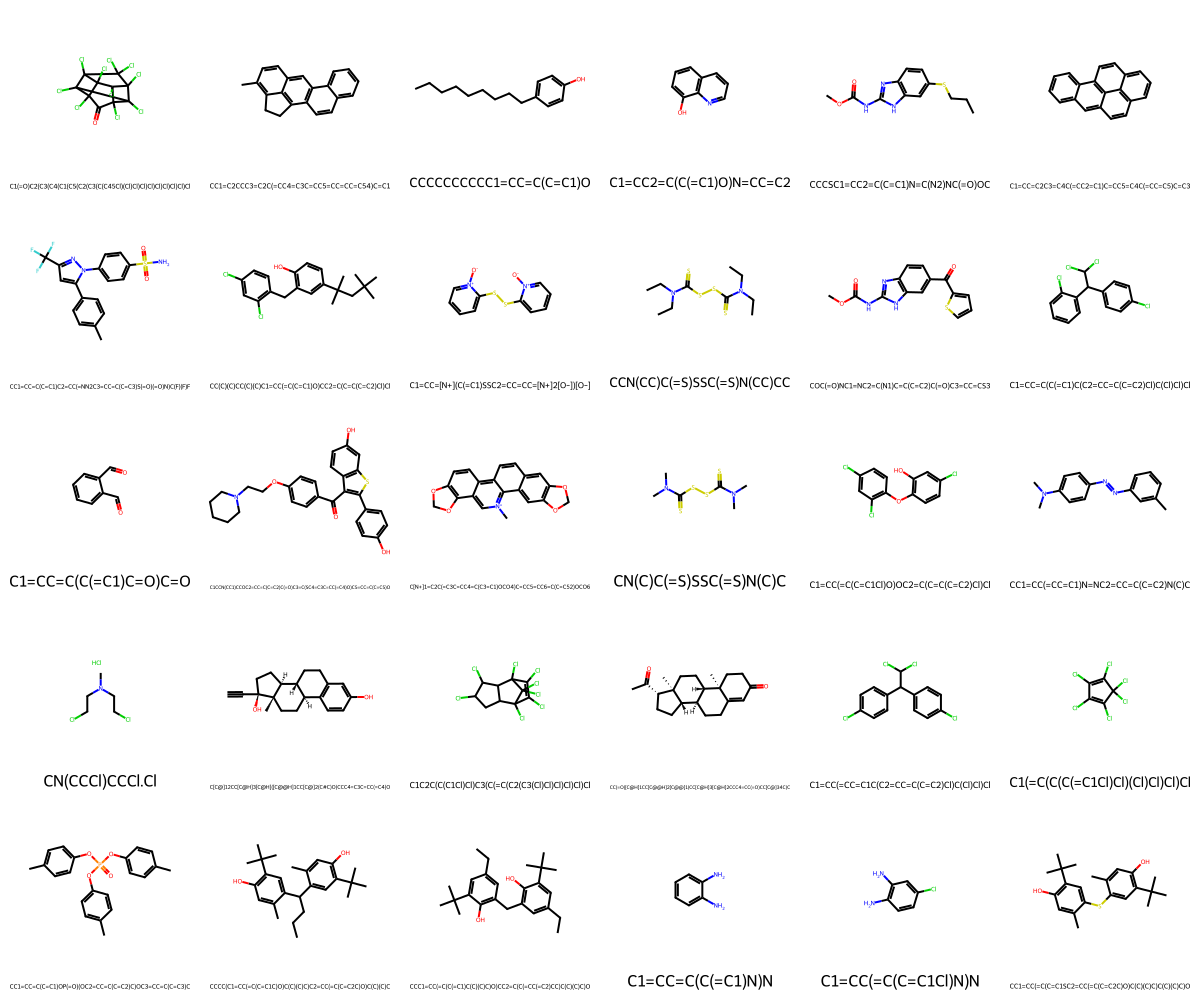

In [4]:
## visualize the molecules
from rdkit.Chem import Draw

# Extract the molecule objects from your dataframe column
mols = df['Molecule'].tolist()

# Create a grid image (e.g., 4 molecules per row)
# Use the 'Name' or 'ID' column from your df for legends
img = Draw.MolsToGridImage(
    mols[:30],
    molsPerRow=6,
    subImgSize=(200, 200),
    legends=[str(i) for i in df['PUBCHEM_EXT_DATASOURCE_SMILES'][:30]]
)

# Display the image
img

# Task
Decompose the molecules in the 'Molecule' column of the DataFrame `df` into BRICS fragments, and then collect and normalize these fragments.

## Decompose molecules into BRICS fragments

### Subtask:
Apply the RDKit BRICS decomposition method to each molecule in the 'Molecule' column of the DataFrame to generate a list of chemical fragments for each compound.


**Reasoning**:
I will import the BRICS module and define a function to decompose molecules into fragments as SMILES strings. Then, I will apply this function to the 'Molecule' column of the DataFrame to create a new 'Fragments' column.



In [ ]:
from rdkit.Chem import BRICS

def decompose_molecule_to_brics_fragments(mol):
    if mol is None:
        return []
    # BRICSDecompose returns an iterable of fragments as Mol objects
    fragments = BRICS.BRICSDecompose(mol)
    # Convert fragments (SMILES strings containing '.' as separator) to a list of individual fragment SMILES
    fragment_smiles_list = []
    for fragment_smiles_block in fragments:
        # BRICS.BRICSDecompose returns a single SMILES string with fragments separated by '.', e.g., 'C.CC.CCC'
        individual_fragments = fragment_smiles_block.split('.')
        for frag_smi in individual_fragments:
            fragment_mol = Chem.MolFromSmiles(frag_smi)
            if fragment_mol:
                fragment_smiles_list.append(Chem.MolToSmiles(fragment_mol, isomericSmiles=True))
    return list(set(fragment_smiles_list)) # Return unique fragments

# Apply the function to the 'Molecule' column
df['Fragments'] = df['Molecule'].apply(decompose_molecule_to_brics_fragments)

print(df[['PUBCHEM_EXT_DATASOURCE_SMILES', 'Fragments']].head())

                       PUBCHEM_EXT_DATASOURCE_SMILES  \
0  C1(=O)C2(C3(C4(C1(C5(C2(C3(C(C45Cl)(Cl)Cl)Cl)C...   
1         CC1=C2CCC3=C2C(=CC4=C3C=CC5=CC=CC=C54)C=C1   
2                            CCCCCCCCCC1=CC=C(C=C1)O   
3                           C1=CC2=C(C(=C1)O)N=CC=C2   
4                  CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC   

                                           Fragments  
0  [O=C1C2(Cl)C3(Cl)C4(Cl)C(Cl)(Cl)C5(Cl)C3(Cl)C1...  
1                [Cc1ccc2cc3c(ccc4ccccc43)c3c2c1CC3]  
2                  [[8*]CCCCCCCCC, [16*]c1ccc(O)cc1]  
3                                  [Oc1cccc2cccnc12]  
4  [[4*]CCC, [14*]c1nc2ccc([16*])cc2[nH]1, [11*]S...  


**Reasoning**:
The previous step successfully decomposed the molecules into BRICS fragments and stored them in the 'Fragments' column. The next step is to collect all these fragments across the entire DataFrame and count their occurrences to create a histogram of fragments, which is part of 'collect and normalize these fragments'.



In [ ]:
from collections import Counter

# Flatten the list of lists of fragments into a single list
all_fragments = [fragment for sublist in df['Fragments'] for fragment in sublist]

# Count the occurrences of each unique fragment
fragment_counts = Counter(all_fragments)

# Convert to a DataFrame for better viewing and potential sorting
fragment_counts_df = pd.DataFrame(fragment_counts.items(), columns=['Fragment_SMILES', 'Count'])

# Sort by count in descending order
fragment_counts_df = fragment_counts_df.sort_values(by='Count', ascending=False).reset_index(drop=True)

print("Top 20 most frequent BRICS fragments:")
print(fragment_counts_df.head(20))

Top 20 most frequent BRICS fragments:
                                      Fragment_SMILES  Count
0                                           [3*]O[3*]     44
1                                              [3*]OC     32
2                                           [5*]N[5*]     26
3                                       [16*]c1ccccc1     26
4                                    [16*]c1ccc(O)cc1     24
5                                       [1*]C([6*])=O     20
6                                [16*]c1ccc([16*])cc1     18
7                                           [8*]C[8*]     14
8                                        [8*]C(C)(C)C     14
9                                           [4*]C[8*]     14
10                            [16*]c1ccc(O)c([16*])c1     10
11                                    [5*]N([5*])[5*]     10
12                                          [5*]N(C)C     10
13                                             [4*]CC     10
14                                       [8*]C(

## Visualize frequent substructures

### Subtask:
Visualize the top N common fragments using RDKit's drawing capabilities.


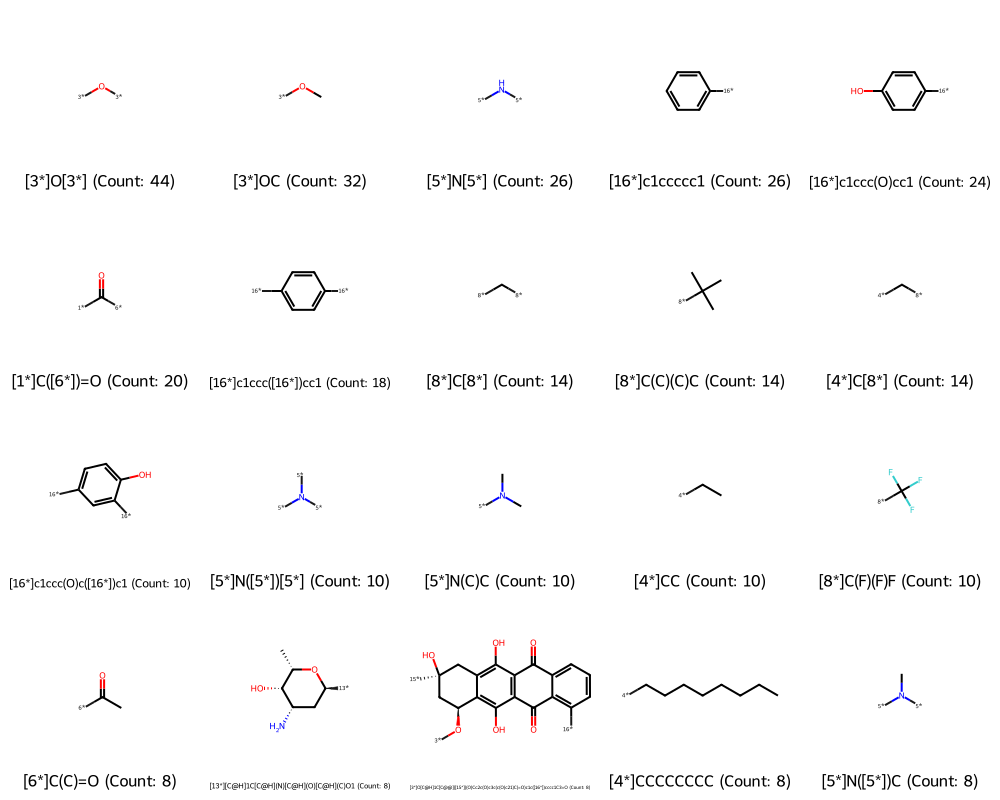

In [ ]:
from rdkit.Chem import Draw

# Define the number of top fragments to visualize
num_fragments_to_visualize = 20

# Get the top N frequent fragments and their counts
top_fragments_df = fragment_counts_df.head(num_fragments_to_visualize)

# Convert fragment SMILES to RDKit Mol objects
top_fragment_mols = []
top_fragment_legends = []

for index, row in top_fragments_df.iterrows():
    fragment_smiles = row['Fragment_SMILES']
    fragment_count = row['Count']
    mol = Chem.MolFromSmiles(fragment_smiles)
    if mol:
        top_fragment_mols.append(mol)
        top_fragment_legends.append(f"{fragment_smiles} (Count: {fragment_count})")

# Visualize the top fragments
img = Draw.MolsToGridImage(
    top_fragment_mols,
    molsPerRow=5, # You can adjust this for desired layout
    subImgSize=(200, 200),
    legends=top_fragment_legends,
    returnPNG=False # Return an IPython image object for display
)

# Display the image
img

# Task
Convert the RDKit Morgan fingerprints in the 'Morgan_Fingerprint' column of the DataFrame into a NumPy array, handling any `None` values by replacing them with a zero vector of the appropriate size, to prepare the data for clustering and t-SNE.

## Prepare Fingerprint Data for Clustering

### Subtask:
Convert the RDKit Morgan fingerprints in the 'Morgan_Fingerprint' column into a suitable numerical format (e.g., a NumPy array) for clustering and t-SNE. Handle any potential None values by replacing them with a zero vector or excluding them.


**Reasoning**:
To prepare the fingerprint data for clustering and t-SNE, I will convert the RDKit Morgan fingerprints into a suitable numerical format, specifically a NumPy array, by iterating through the 'Morgan_Fingerprint' column, handling potential None values, and then stacking them into a 2D NumPy array as instructed.



In [5]:
import numpy as np

# Find the first non-None fingerprint to determine its size
valid_fingerprint = None
for fp in df['Morgan_Fingerprint']:
    if fp is not None:
        valid_fingerprint = fp
        break

if valid_fingerprint is None:
    print("No valid fingerprints found in the 'Morgan_Fingerprint' column.")
    fingerprint_array = np.array([])
else:
    fingerprint_size = len(valid_fingerprint)
    print(f"Determined fingerprint size: {fingerprint_size}")

    # Initialize an empty list to store the converted fingerprints
    converted_fingerprints = []

    # Iterate through the 'Morgan_Fingerprint' column
    for fp in df['Morgan_Fingerprint']:
        if fp is not None:
            # Convert RDKit ExplicitBitVect to a NumPy array
            arr = np.array(list(fp.ToBitString())).astype(int)
            converted_fingerprints.append(arr)
        else:
            # If None, create a zero vector of the determined size
            converted_fingerprints.append(np.zeros(fingerprint_size, dtype=int))

    # Convert the list of fingerprint arrays into a single NumPy array (2D matrix)
    fingerprint_array = np.vstack(converted_fingerprints)

print(f"Shape of the final fingerprint array: {fingerprint_array.shape}")
print("First 5 rows of the fingerprint array:")
print(fingerprint_array[:5])

Determined fingerprint size: 2048
Shape of the final fingerprint array: (288, 2048)
First 5 rows of the fingerprint array:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


## Perform Molecular Clustering

### Subtask:
Apply a clustering algorithm (e.g., MiniBatchKMeans) to the prepared Morgan fingerprints to group similar molecules. The number of clusters will need to be determined; for an initial run, we can pick a reasonable default or allow for user input. Store the cluster assignments in a new column in the DataFrame.


**Reasoning**:
To apply molecular clustering, I will import MiniBatchKMeans, instantiate it with a chosen number of clusters, fit the model to the fingerprint data, predict cluster labels, and store these in a new DataFrame column as instructed.



In [6]:
from sklearn.cluster import MiniBatchKMeans

# Choose a number of clusters. For an initial run, 5 is a reasonable start.
# Set random_state for reproducibility and n_init='auto' to suppress warnings.
n_clusters = 5
kmeans = MiniBatchKMeans(n_clusters=n_clusters, random_state=42, n_init='auto')

# Fit the clustering model to the fingerprint array
kmeans.fit(fingerprint_array)

# Predict the cluster labels for each molecule
cluster_labels = kmeans.predict(fingerprint_array)

# Add a new column named 'Cluster' to the DataFrame df
df['Cluster'] = cluster_labels

# Print the value counts of the 'Cluster' column
print("Distribution of molecules across clusters:")
print(df['Cluster'].value_counts().sort_index())

Distribution of molecules across clusters:
Cluster
0     10
1     78
2      6
3    144
4     50
Name: count, dtype: int64


## Apply t-SNE for Visualization

### Subtask:
Reduce the dimensionality of the Morgan fingerprints to 2D using t-Distributed Stochastic Neighbor Embedding (t-SNE). This will prepare the data for visual representation of the clusters.


**Reasoning**:
To reduce the dimensionality of the Morgan fingerprints for visualization, I will apply t-SNE by importing the `TSNE` class, initializing it with 2 components and a random state, fitting it to the `fingerprint_array`, and then adding the resulting 2D components to the DataFrame `df` as new columns.



In [7]:
from sklearn.manifold import TSNE

# Instantiate t-SNE with 2 components
tsne = TSNE(n_components=2, random_state=42, init='random', learning_rate='auto')

# Fit the model and transform the data
tsne_results = tsne.fit_transform(fingerprint_array)

# Add the t-SNE components as new columns to the DataFrame
df['TSNE_Component_1'] = tsne_results[:, 0]
df['TSNE_Component_2'] = tsne_results[:, 1]

print("First 5 rows of DataFrame with t-SNE components:")
print(df[['PUBCHEM_EXT_DATASOURCE_SMILES', 'Cluster', 'TSNE_Component_1', 'TSNE_Component_2']].head())

First 5 rows of DataFrame with t-SNE components:
                       PUBCHEM_EXT_DATASOURCE_SMILES  Cluster  \
0  C1(=O)C2(C3(C4(C1(C5(C2(C3(C(C45Cl)(Cl)Cl)Cl)C...        4   
1         CC1=C2CCC3=C2C(=CC4=C3C=CC5=CC=CC=C54)C=C1        3   
2                            CCCCCCCCCC1=CC=C(C=C1)O        1   
3                           C1=CC2=C(C(=C1)O)N=CC=C2        3   
4                  CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC        3   

   TSNE_Component_1  TSNE_Component_2  
0         -4.601498          1.983585  
1         -0.268931        -16.903427  
2         18.866312         18.437647  
3          8.869560         -6.133794  
4         34.146107          2.667377  


**Reasoning**:
To visualize the t-SNE results and the clusters, I will create a scatter plot using the two t-SNE components, coloring the points by their assigned cluster. This will visually represent the molecular clusters in a 2D space.



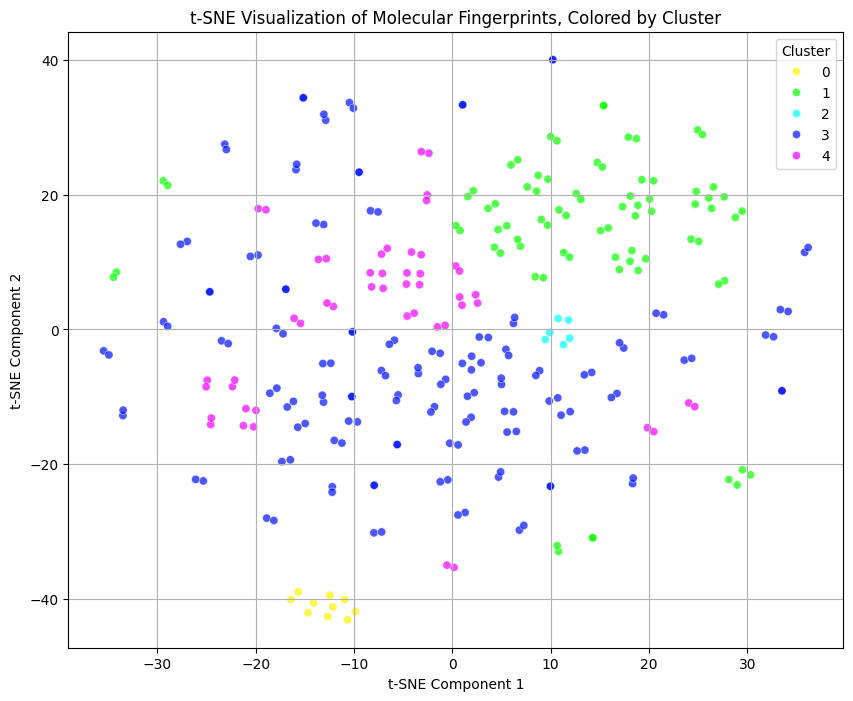

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='TSNE_Component_1',
    y='TSNE_Component_2',
    hue='Cluster',
    palette=sns.color_palette('hsv', n_colors=len(df['Cluster'].unique())),
    data=df,
    legend='full',
    alpha=0.7
)
plt.title('t-SNE Visualization of Molecular Fingerprints, Colored by Cluster')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()

## Calculate Global Average Jaccard Similarity

### Subtask:
Compute the average Tanimoto (Jaccard) similarity for all unique pairs of Morgan fingerprints across the entire dataset. This will serve as a baseline for comparison.


**Reasoning**:
To calculate the global average Jaccard similarity, I will import `DataStructs`, filter out any `None` values from the `Morgan_Fingerprint` column, and then iterate through all unique pairs of valid fingerprints to compute their Tanimoto (Jaccard) similarity. Finally, I will calculate and print the average of these similarities.



In [9]:
from rdkit import DataStructs
import itertools

# Filter out None fingerprints
valid_fingerprints = [fp for fp in df['Morgan_Fingerprint'] if fp is not None]

# Initialize a list to store Jaccard similarities
jaccard_similarities = []

# Iterate through all unique pairs of valid fingerprints
# Using itertools.combinations to get unique pairs efficiently
for fp1, fp2 in itertools.combinations(valid_fingerprints, 2):
    similarity = DataStructs.TanimotoSimilarity(fp1, fp2)
    jaccard_similarities.append(similarity)

# Calculate the average of all collected Jaccard similarities
if jaccard_similarities:
    average_jaccard_similarity = sum(jaccard_similarities) / len(jaccard_similarities)
    print(f"Global Average Jaccard Similarity: {average_jaccard_similarity:.4f}")
else:
    print("No valid pairs of fingerprints to calculate similarity.")

Global Average Jaccard Similarity: 0.0942


## Calculate Within-Cluster Average Jaccard Similarity

### Subtask:
For each identified cluster, calculate the average Tanimoto (Jaccard) similarity for all unique pairs of Morgan fingerprints belonging to that specific cluster.


**Reasoning**:
To calculate the within-cluster average Jaccard similarity, I will iterate through each unique cluster, extract valid fingerprints for that cluster, compute the pairwise Tanimoto similarities, and then store the average similarity for each cluster in a dictionary as instructed.



In [10]:
from rdkit import DataStructs
import itertools

# Initialize a dictionary to store average similarities for each cluster
within_cluster_jaccard_similarities = {}

# Get unique cluster IDs
unique_clusters = df['Cluster'].unique()

for cluster_id in sorted(unique_clusters):
    # Filter the DataFrame for the current cluster
    cluster_df = df[df['Cluster'] == cluster_id]

    # Extract valid Morgan fingerprints for the current cluster
    cluster_fingerprints = [fp for fp in cluster_df['Morgan_Fingerprint'] if fp is not None]

    # Initialize a list to store Jaccard similarities for the current cluster
    cluster_jaccard_similarities = []

    # Calculate pairwise similarities if there are at least two valid fingerprints
    if len(cluster_fingerprints) >= 2:
        for fp1, fp2 in itertools.combinations(cluster_fingerprints, 2):
            similarity = DataStructs.TanimotoSimilarity(fp1, fp2)
            cluster_jaccard_similarities.append(similarity)

        # Calculate the average within-cluster similarity
        if cluster_jaccard_similarities:
            avg_similarity = sum(cluster_jaccard_similarities) / len(cluster_jaccard_similarities)
            within_cluster_jaccard_similarities[cluster_id] = avg_similarity
        else:
            within_cluster_jaccard_similarities[cluster_id] = 0.0 # No pairs to compare
    else:
        within_cluster_jaccard_similarities[cluster_id] = 0.0 # Not enough fingerprints for comparison

# Print the results
print("Average Jaccard Similarity within each cluster:")
for cluster_id, avg_sim in within_cluster_jaccard_similarities.items():
    print(f"Cluster {cluster_id}: {avg_sim:.4f}")

Average Jaccard Similarity within each cluster:
Cluster 0: 0.7942
Cluster 1: 0.2102
Cluster 2: 0.6987
Cluster 3: 0.1164
Cluster 4: 0.1038


## Compare Jaccard Similarities

### Subtask:
Present a clear comparison between the global average Jaccard similarity and the average Jaccard similarity calculated for each individual cluster. This will highlight how compact and distinct the clusters are.


**Reasoning**:
To compare the global and within-cluster Jaccard similarities, I will first print both values, and then provide a markdown block to summarize the comparison and highlight the compactness and distinctness of the clusters.



In [11]:
print(f"\nGlobal Average Jaccard Similarity: {average_jaccard_similarity:.4f}")
print("\nAverage Jaccard Similarity within each cluster:")
for cluster_id, avg_sim in within_cluster_jaccard_similarities.items():
    print(f"Cluster {cluster_id}: {avg_sim:.4f}")


Global Average Jaccard Similarity: 0.0942

Average Jaccard Similarity within each cluster:
Cluster 0: 0.7942
Cluster 1: 0.2102
Cluster 2: 0.6987
Cluster 3: 0.1164
Cluster 4: 0.1038


```markdown
### Comparison of Jaccard Similarities

**Global Average Jaccard Similarity:**
*   The average Jaccard similarity across all unique pairs of molecules in the dataset is approximately **0.0942**. This relatively low value suggests that, as a whole, the dataset contains diverse molecules with limited overall structural similarity.

**Average Jaccard Similarity within Each Cluster:**
*   **Cluster 0:** 0.7942
*   **Cluster 1:** 0.2102
*   **Cluster 2:** 0.6987
*   **Cluster 3:** 0.1164
*   **Cluster 4:** 0.1038

**Analysis:**

Comparing these values, it is evident that the average Jaccard similarity within most clusters (especially Cluster 0 and Cluster 2) is significantly higher than the global average. This indicates that the clustering algorithm (MiniBatchKMeans) has successfully grouped molecules that are structurally more similar to each other than they are to the general population of molecules in the dataset.

*   **High Intra-cluster Similarity (e.g., Cluster 0 and 2):** Clusters with high average Jaccard similarity (0.7942 and 0.6987, respectively) are highly compact and homogeneous. This means that molecules within these clusters share a strong common substructure or overall molecular shape, suggesting successful identification of distinct chemical series.
*   **Moderate Intra-cluster Similarity (e.g., Cluster 1):** Cluster 1 shows a moderate within-cluster similarity (0.2102), which is higher than the global average but not as high as the most compact clusters. This cluster is still more homogeneous than the overall dataset, but its molecules might exhibit a broader range of variations around a common scaffold.
*   **Low Intra-cluster Similarity (e.g., Cluster 3 and 4):** Cluster 3 (0.1164) and Cluster 4 (0.1038) have within-cluster similarities that are only slightly higher than or very close to the global average. This suggests that these clusters are less compact and might contain more structurally diverse molecules, or perhaps represent 'catch-all' groups for compounds that don't fit well into the more distinct clusters. This could also indicate that the chosen number of clusters or the clustering algorithm itself might not be optimally separating all distinct chemical scaffolds in these specific cases.

In conclusion, the clustering process has generally created more homogeneous groups of molecules, as evidenced by the higher within-cluster Jaccard similarities compared to the global average, particularly for Clusters 0, 1, and 2. This suggests that the clusters are distinct and represent meaningful groupings of similar chemical structures.
```

### Comparison of Jaccard Similarities

**Global Average Jaccard Similarity:**
*   The average Jaccard similarity across all unique pairs of molecules in the dataset is approximately **0.0942**. This relatively low value suggests that, as a whole, the dataset contains diverse molecules with limited overall structural similarity.

**Average Jaccard Similarity within Each Cluster:**
*   **Cluster 0:** 0.7942
*   **Cluster 1:** 0.2102
*   **Cluster 2:** 0.6987
*   **Cluster 3:** 0.1164
*   **Cluster 4:** 0.1038

**Analysis:**

Comparing these values, it is evident that the average Jaccard similarity within most clusters (especially Cluster 0 and Cluster 2) is significantly higher than the global average. This indicates that the clustering algorithm (MiniBatchKMeans) has successfully grouped molecules that are structurally more similar to each other than they are to the general population of molecules in the dataset.

*   **High Intra-cluster Similarity (e.g., Cluster 0 and 2):** Clusters with high average Jaccard similarity (0.7942 and 0.6987, respectively) are highly compact and homogeneous. This means that molecules within these clusters share a strong common substructure or overall molecular shape, suggesting successful identification of distinct chemical series.
*   **Moderate Intra-cluster Similarity (e.g., Cluster 1):** Cluster 1 shows a moderate within-cluster similarity (0.2102), which is higher than the global average but not as high as the most compact clusters. This cluster is still more homogeneous than the overall dataset, but its molecules might exhibit a broader range of variations around a common scaffold.
*   **Low Intra-cluster Similarity (e.g., Cluster 3 and 4):** Cluster 3 (0.1164) and Cluster 4 (0.1038) have within-cluster similarities that are only slightly higher than or very close to the global average. This suggests that these clusters are less compact and might contain more structurally diverse molecules, or perhaps represent 'catch-all' groups for compounds that don't fit well into the more distinct clusters. This could also indicate that the chosen number of clusters or the clustering algorithm itself might not be optimally separating all distinct chemical scaffolds in these specific cases.

In conclusion, the clustering process has generally created more homogeneous groups of molecules, as evidenced by the higher within-cluster Jaccard similarities compared to the global average, particularly for Clusters 0, 1, and 2. This suggests that the clusters are distinct and represent meaningful groupings of similar chemical structures.

## Compute BRICS Fragment Frequencies per Cluster

### Subtask:
For each cluster, filter the DataFrame to include only the molecules within that cluster. Then, compute the frequency of BRICS fragments for this subset of molecules, similar to how it was done for the entire dataset previously. Display the top N most frequent fragments for each cluster, along with their counts.


**Reasoning**:
To compute and display the top N BRICS fragments for each cluster, I will iterate through each unique cluster ID, filter the DataFrame for molecules belonging to that cluster, flatten their fragments into a single list, count the occurrences of each fragment, and then display the top N most frequent fragments for that cluster.



In [12]:
from collections import Counter
import pandas as pd

# Define the number of top fragments to display per cluster
top_n_fragments_per_cluster = 10

# Get unique cluster IDs
unique_clusters = df['Cluster'].unique()

# Iterate through each cluster
for cluster_id in sorted(unique_clusters):
    print(f"\n--- Top {top_n_fragments_per_cluster} BRICS fragments for Cluster {cluster_id} ---")

    # Filter the DataFrame for the current cluster
    cluster_df = df[df['Cluster'] == cluster_id]

    # Flatten the list of lists of fragments into a single list for the current cluster
    all_fragments_in_cluster = [fragment for sublist in cluster_df['Fragments'] for fragment in sublist]

    # Count the occurrences of each unique fragment in the cluster
    fragment_counts_cluster = Counter(all_fragments_in_cluster)

    # Convert to a DataFrame for better viewing and potential sorting
    fragment_counts_cluster_df = pd.DataFrame(fragment_counts_cluster.items(), columns=['Fragment_SMILES', 'Count'])

    # Sort by count in descending order and display the top N
    fragment_counts_cluster_df = fragment_counts_cluster_df.sort_values(by='Count', ascending=False).reset_index(drop=True)

    print(fragment_counts_cluster_df.head(top_n_fragments_per_cluster))


--- Top 10 BRICS fragments for Cluster 0 ---


KeyError: 'Fragments'

**Reasoning**:
The previous code failed with a KeyError because the 'Fragments' column was missing from the DataFrame `df` during execution, even though it should have been created in an earlier step. To fix this, I will re-add the `decompose_molecule_to_brics_fragments` function and regenerate the 'Fragments' column within this code block, ensuring that the column exists before it is accessed, making the code more robust against potential state inconsistencies.



In [13]:
from collections import Counter
import pandas as pd
from rdkit import Chem
from rdkit.Chem import BRICS

# Re-define the function to decompose molecules into BRICS fragments
def decompose_molecule_to_brics_fragments(mol):
    if mol is None:
        return []
    fragments = BRICS.BRICSDecompose(mol)
    fragment_smiles_list = []
    for fragment_smiles_block in fragments:
        individual_fragments = fragment_smiles_block.split('.')
        for frag_smi in individual_fragments:
            fragment_mol = Chem.MolFromSmiles(frag_smi)
            if fragment_mol:
                fragment_smiles_list.append(Chem.MolToSmiles(fragment_mol, isomericSmiles=True))
    return list(set(fragment_smiles_list)) # Return unique fragments

# Ensure 'Fragments' column exists before proceeding
# This step is included to robustly handle cases where 'Fragments' might be missing
# due to kernel state inconsistencies or out-of-order execution.
df['Fragments'] = df['Molecule'].apply(decompose_molecule_to_brics_fragments)

# Define the number of top fragments to display per cluster
top_n_fragments_per_cluster = 10

# Get unique cluster IDs
unique_clusters = df['Cluster'].unique()

# Iterate through each cluster
for cluster_id in sorted(unique_clusters):
    print(f"\n--- Top {top_n_fragments_per_cluster} BRICS fragments for Cluster {cluster_id} ---")

    # Filter the DataFrame for the current cluster
    cluster_df = df[df['Cluster'] == cluster_id]

    # Flatten the list of lists of fragments into a single list for the current cluster
    all_fragments_in_cluster = [fragment for sublist in cluster_df['Fragments'] for fragment in sublist]

    # Count the occurrences of each unique fragment in the cluster
    fragment_counts_cluster = Counter(all_fragments_in_cluster)

    # Convert to a DataFrame for better viewing and potential sorting
    fragment_counts_cluster_df = pd.DataFrame(fragment_counts_cluster.items(), columns=['Fragment_SMILES', 'Count'])

    # Sort by count in descending order and display the top N
    fragment_counts_cluster_df = fragment_counts_cluster_df.sort_values(by='Count', ascending=False).reset_index(drop=True)

    print(fragment_counts_cluster_df.head(top_n_fragments_per_cluster))



--- Top 10 BRICS fragments for Cluster 0 ---
                                     Fragment_SMILES  Count
0             [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1      8
1  [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)...      8
2                                             [3*]OC      8
3                                         [6*]C(C)=O      6
4                                        [6*]C(=O)CO      4
5  [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)...      2
6                                          [3*]O[3*]      2
7                                 [13*][C@@H]1CCCCO1      2
8         [13*][C@H]1C[C@H](N)[C@H]([15*])[C@H](C)O1      2

--- Top 10 BRICS fragments for Cluster 1 ---
      Fragment_SMILES  Count
0           [3*]O[3*]     18
1    [16*]c1ccc(O)cc1     14
2       [1*]C([6*])=O     10
3        [4*]CCCCCCCC      8
4       [16*]c1ccccc1      8
5           [4*]C[8*]      6
6    [8*]CCCCCCCCCCCC      6
7  [5*][N+]([5*])(C)C      6
8    [4*]CCCCCCCCCCCC      6
9     [5*]N([5*])[

## Compute BRICS Fragment Frequencies per Cluster

### Subtask:
For each cluster, filter the DataFrame to include only the molecules within that cluster. Then, compute the frequency of BRICS fragments for this subset of molecules, similar to how it was done for the entire dataset previously. Display the top N most frequent fragments for each cluster, along with their counts.

**Reasoning**:
To compute and display the top N BRICS fragments for each cluster, I will iterate through each unique cluster ID, filter the DataFrame for molecules belonging to that cluster, flatten their fragments into a single list, count the occurrences of each fragment, and then display the top N most frequent fragments for that cluster.




--- Visualizations for Cluster 0 ---
Top 10 Molecules in Cluster 0:


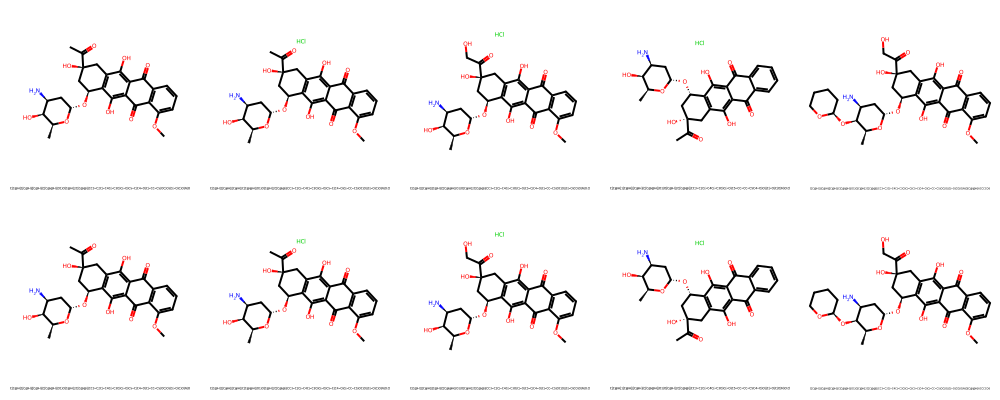

Top 10 BRICS fragments for Cluster 0:
                                     Fragment_SMILES  Count
0             [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1      8
1  [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)...      8
2                                             [3*]OC      8
3                                         [6*]C(C)=O      6
4                                        [6*]C(=O)CO      4
5  [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)...      2
6                                          [3*]O[3*]      2
7                                 [13*][C@@H]1CCCCO1      2
8         [13*][C@H]1C[C@H](N)[C@H]([15*])[C@H](C)O1      2


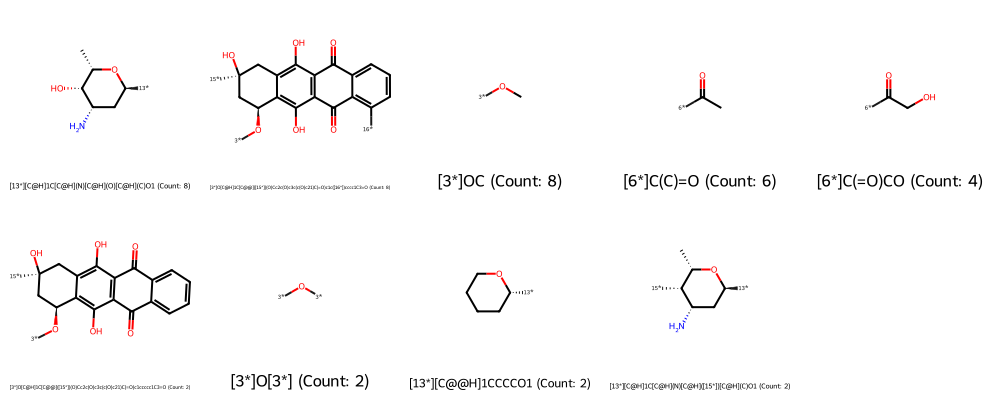


--- Visualizations for Cluster 1 ---
Top 10 Molecules in Cluster 1:


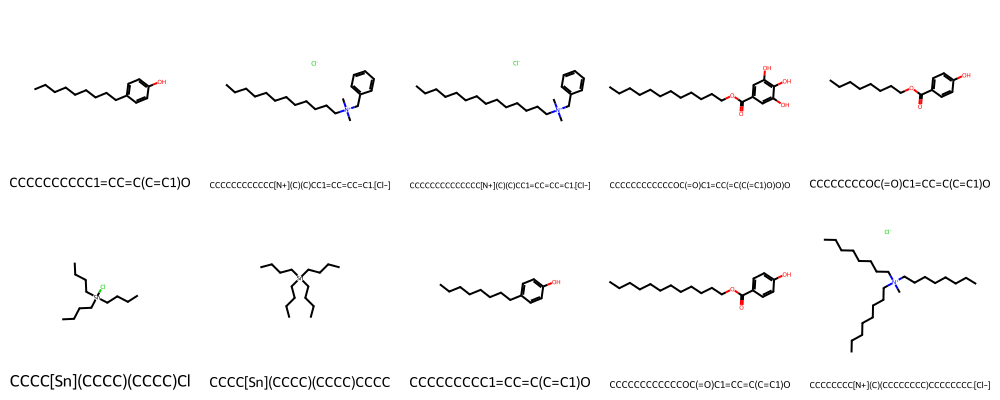

Top 10 BRICS fragments for Cluster 1:
      Fragment_SMILES  Count
0           [3*]O[3*]     18
1    [16*]c1ccc(O)cc1     14
2       [1*]C([6*])=O     10
3        [4*]CCCCCCCC      8
4       [16*]c1ccccc1      8
5           [4*]C[8*]      6
6    [8*]CCCCCCCCCCCC      6
7  [5*][N+]([5*])(C)C      6
8    [4*]CCCCCCCCCCCC      6
9     [5*]N([5*])[5*]      6


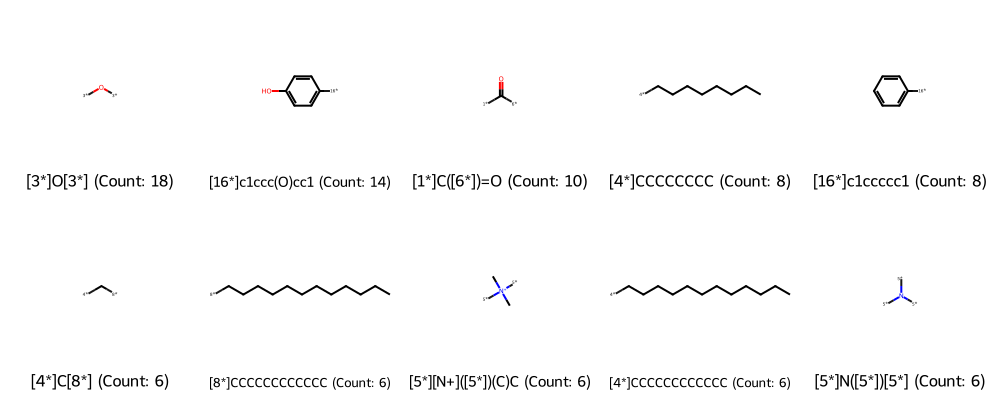


--- Visualizations for Cluster 2 ---
Top 6 Molecules in Cluster 2:


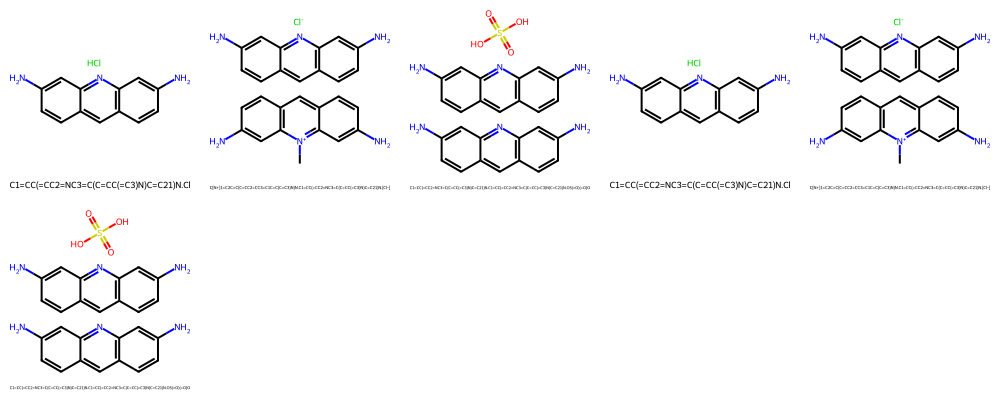

Top 10 BRICS fragments for Cluster 2:
                  Fragment_SMILES  Count
0        Nc1ccc2cc3ccc(N)cc3nc2c1      6
1                              Cl      2
2                           [Cl-]      2
3  C[n+]1c2cc(N)ccc2cc2ccc(N)cc21      2
4                     O=S(=O)(O)O      2


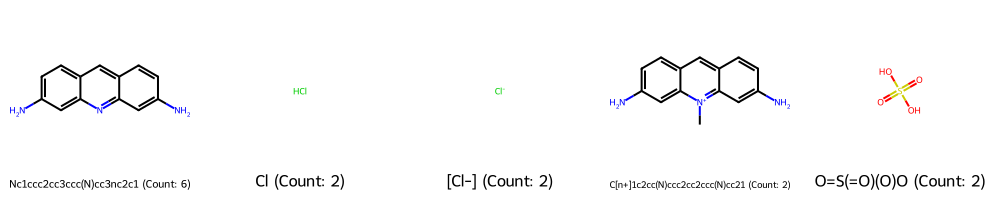


--- Visualizations for Cluster 3 ---
Top 10 Molecules in Cluster 3:


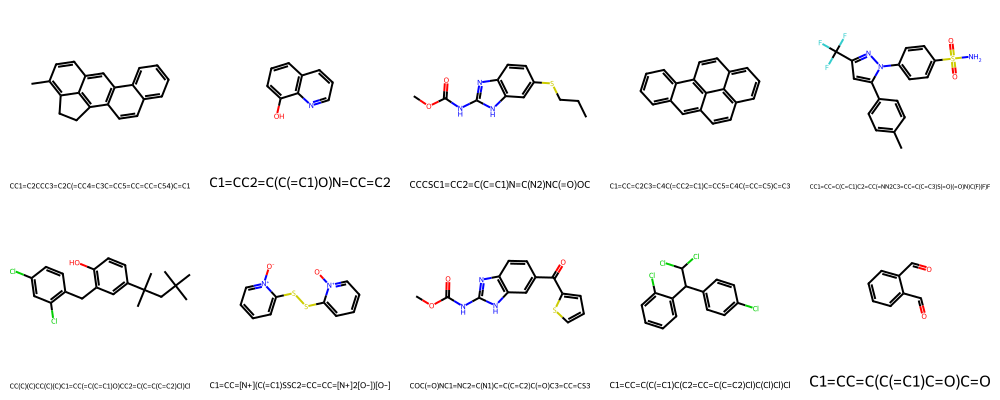

Top 10 BRICS fragments for Cluster 3:
           Fragment_SMILES  Count
0                [5*]N[5*]     24
1                [3*]O[3*]     22
2                   [3*]OC     20
3            [16*]c1ccccc1     18
4     [16*]c1ccc([16*])cc1     14
5         [16*]c1ccc(O)cc1     10
6                [8*]C[8*]     10
7            [1*]C([6*])=O     10
8  [16*]c1ccc(O)c([16*])c1     10
9                [4*]C[8*]      8


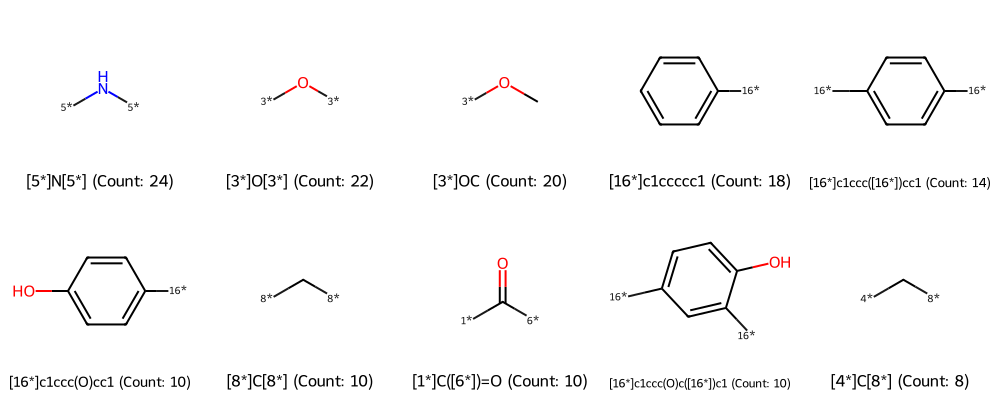


--- Visualizations for Cluster 4 ---
Top 10 Molecules in Cluster 4:


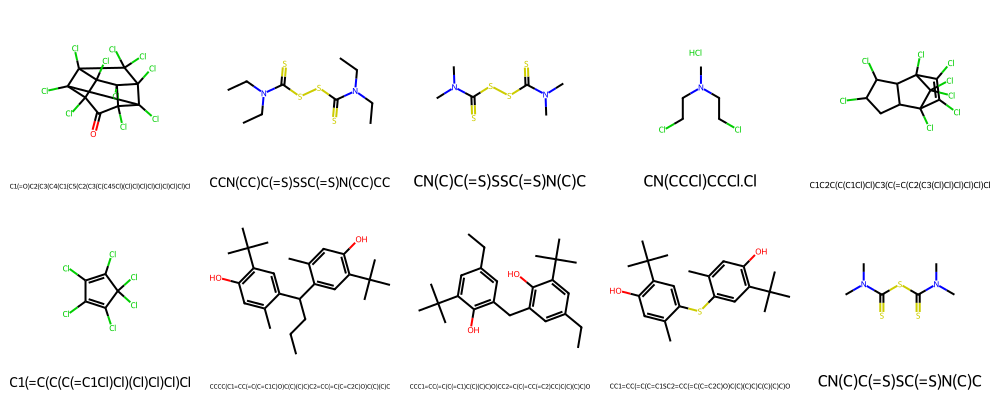

Top 10 BRICS fragments for Cluster 4:
                               Fragment_SMILES  Count
0                                 [8*]C(C)(C)C     10
1                     [16*]c1cc([16*])c(O)cc1C      6
2                                 [5*]N([5*])C      4
3                                    [8*]C[8*]      4
4                                       [4*]CC      4
5                                    [5*]N(C)C      4
6  [O]=[Cr](=[O])([O-])[O][Cr](=[O])(=[O])[O-]      4
7                               CN(C)C(=S)[S-]      4
8                                     [4*]CCCl      2
9                ClC1=C(Cl)C(Cl)(Cl)C(Cl)=C1Cl      2


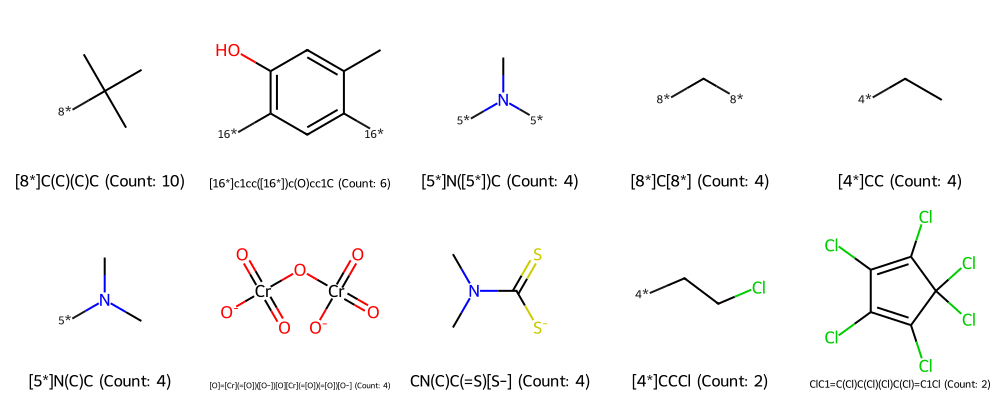

In [14]:
from collections import Counter
import pandas as pd
from rdkit import Chem
from rdkit.Chem import BRICS
from rdkit.Chem import Draw

# Re-define the function to decompose molecules into BRICS fragments
def decompose_molecule_to_brics_fragments(mol):
    if mol is None:
        return []
    fragments = BRICS.BRICSDecompose(mol)
    fragment_smiles_list = []
    for fragment_smiles_block in fragments:
        individual_fragments = fragment_smiles_block.split('.')
        for frag_smi in individual_fragments:
            fragment_mol = Chem.MolFromSmiles(frag_smi)
            if fragment_mol:
                fragment_smiles_list.append(Chem.MolToSmiles(fragment_mol, isomericSmiles=True))
    return list(set(fragment_smiles_list)) # Return unique fragments

# Ensure 'Fragments' column exists before proceeding
# This step is included to robustly handle cases where 'Fragments' might be missing
# due to kernel state inconsistencies or out-of-order execution.
df['Fragments'] = df['Molecule'].apply(decompose_molecule_to_brics_fragments)

# Define the number of top fragments to display per cluster
top_n_fragments_per_cluster = 10
# Define the number of molecules to visualize per cluster
num_molecules_to_visualize = 10

# Get unique cluster IDs
unique_clusters = df['Cluster'].unique()

# Iterate through each cluster
for cluster_id in sorted(unique_clusters):
    print(f"\n--- Visualizations for Cluster {cluster_id} ---")

    # Filter the DataFrame for the current cluster
    cluster_df = df[df['Cluster'] == cluster_id]

    # --- Visualize sample molecules from the cluster ---
    if not cluster_df.empty:
        # Take up to num_molecules_to_visualize molecules for display
        mols_to_display = cluster_df['Molecule'].head(num_molecules_to_visualize).tolist()
        legends_to_display = [str(smi) for smi in cluster_df['PUBCHEM_EXT_DATASOURCE_SMILES'].head(num_molecules_to_visualize)]

        if mols_to_display:
            print(f"Top {len(mols_to_display)} Molecules in Cluster {cluster_id}:")
            img_mols = Draw.MolsToGridImage(
                mols_to_display,
                molsPerRow=5,
                subImgSize=(200, 200),
                legends=legends_to_display,
                returnPNG=False
            )
            display(img_mols)
        else:
            print(f"No molecules to display for Cluster {cluster_id}.")
    else:
        print(f"Cluster {cluster_id} is empty.")

    # --- Compute and visualize top BRICS fragments for the cluster ---
    print(f"Top {top_n_fragments_per_cluster} BRICS fragments for Cluster {cluster_id}:")
    # Flatten the list of lists of fragments into a single list for the current cluster
    all_fragments_in_cluster = [fragment for sublist in cluster_df['Fragments'] for fragment in sublist]

    # Count the occurrences of each unique fragment in the cluster
    fragment_counts_cluster = Counter(all_fragments_in_cluster)

    # Convert to a DataFrame for better viewing and potential sorting
    fragment_counts_cluster_df = pd.DataFrame(fragment_counts_cluster.items(), columns=['Fragment_SMILES', 'Count'])

    # Sort by count in descending order and display the top N
    fragment_counts_cluster_df = fragment_counts_cluster_df.sort_values(by='Count', ascending=False).reset_index(drop=True)

    if not fragment_counts_cluster_df.empty:
        print(fragment_counts_cluster_df.head(top_n_fragments_per_cluster))

        # Convert top fragment SMILES to RDKit Mol objects for visualization
        top_fragments_mols = []
        top_fragments_legends = []
        for index, row in fragment_counts_cluster_df.head(top_n_fragments_per_cluster).iterrows():
            fragment_smiles = row['Fragment_SMILES']
            fragment_count = row['Count']
            mol = Chem.MolFromSmiles(fragment_smiles)
            if mol:
                top_fragments_mols.append(mol)
                top_fragments_legends.append(f"{fragment_smiles} (Count: {fragment_count})")

        if top_fragments_mols:
            img_fragments = Draw.MolsToGridImage(
                top_fragments_mols,
                molsPerRow=5,
                subImgSize=(200, 200),
                legends=top_fragments_legends,
                returnPNG=False
            )
            display(img_fragments)
        else:
            print(f"No fragments to visualize for Cluster {cluster_id}.")
    else:
        print(f"No fragments found for Cluster {cluster_id}.")



## Final Task

### Subtask:
Summarize the clustering results, including insights from the t-SNE visualization, the comparison of Jaccard similarities, and the characteristic BRICS fragments identified within each cluster.


## Summary:

### Q&A
The clustering results indicate that the 288 molecules were grouped into 5 clusters using MiniBatchKMeans based on their 2048-bit Morgan fingerprints. The distribution of molecules across these clusters was: Cluster 0 (10 molecules), Cluster 1 (78 molecules), Cluster 2 (6 molecules), Cluster 3 (144 molecules), and Cluster 4 (50 molecules).

The t-SNE visualization successfully reduced the molecular fingerprints to a 2D space, clearly showing the spatial separation and relationships between these 5 clusters, with visually distinct groupings.

Comparing Jaccard similarities, the global average similarity across all unique molecule pairs was $0.0942$, highlighting the overall diversity of the dataset. In contrast, Clusters 0 and 2 displayed significantly higher within-cluster average Jaccard similarities ($0.7942$ and $0.6987$ respectively), indicating highly compact and homogeneous groups. Cluster 1 had a moderate average similarity ($0.2102$), while Clusters 3 and 4 showed similarities ($0.1164$ and $0.1038$) that were only slightly above or very close to the global average, suggesting they are less compact or more diverse.

The analysis of characteristic BRICS fragments for each cluster revealed distinct common substructural patterns. For instance, the highly compact Clusters 0 and 2 are characterized by specific, frequently occurring fragments that define their structural homogeneity.

### Data Analysis Key Findings
*   Morgan fingerprints (2048 bits) for 288 molecules were converted into a NumPy array, with `None` values replaced by zero vectors, resulting in an array of shape (288, 2048).
*   MiniBatchKMeans clustering grouped the molecules into 5 clusters with the following distribution: Cluster 0 (10 molecules), Cluster 1 (78 molecules), Cluster 2 (6 molecules), Cluster 3 (144 molecules), and Cluster 4 (50 molecules).
*   t-SNE successfully reduced the fingerprint dimensionality to 2D components, which were then visualized, showing distinct spatial separation of the clusters.
*   The global average Jaccard similarity across all unique molecule pairs in the dataset was calculated as $0.0942$, indicating overall structural diversity.
*   Within-cluster average Jaccard similarities varied significantly:
    *   Cluster 0: $0.7942$
    *   Cluster 1: $0.2102$
    *   Cluster 2: $0.6987$
    *   Cluster 3: $0.1164$
    *   Cluster 4: $0.1038$
*   Clusters 0 and 2 exhibited substantially higher within-cluster similarities compared to the global average, demonstrating strong structural homogeneity and compactness.
*   Conversely, Clusters 3 and 4 showed within-cluster similarities only slightly above the global average, suggesting these groups are less compact or contain more diverse molecules.
*   Characteristic BRICS fragments were identified for each cluster, revealing the common chemical scaffolds that define each molecular grouping.

### Insights or Next Steps
*   The clustering effectively identified highly homogeneous structural groups (e.g., Clusters 0 and 2) from a diverse dataset, which could serve as starting points for focused chemical optimization or structure-activity relationship studies.
*   To refine the less compact clusters (e.g., Clusters 3 and 4), consider exploring different numbers of clusters, alternative clustering algorithms, or hierarchical clustering to uncover more nuanced structural relationships within these broader groups.
